*****Partie 1 : Introduction au Dataset*****

**Téléchargement de  dataset**

In [283]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.preprocessing import StandardScaler
path = os.path.expanduser("~/Desktop/master/aprentissage/titanic.xls")
df = pd.read_excel(path)

***Les demention de dataset***

In [284]:
print(df.shape)

(1309, 14)


***Identifiez les types de données (numériques, catégorielles).***

In [339]:

num_col = df.select_dtypes(include=['int64', 'float64']).columns
cat_col = df.select_dtypes(include=['object', 'category']).columns
print("les Colonnes numériques :")
print(num_col)
print("\n les Colonnes catégorielles :")
print(cat_col)

les Colonnes numériques :
Index(['pclass', 'survived', 'age', 'sibsp', 'parch', 'fare', 'body',
       'sex_female', 'sex_male', 'embarked_C', 'embarked_Q', 'embarked_S'],
      dtype='object')

 les Colonnes catégorielles :
Index(['name', 'ticket', 'cabin', 'boat', 'home.dest'], dtype='object')


***Visualisez les premières lignes du dataset.***

In [286]:
df.head () 


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


***Vérifiez les valeurs manquantes avec df.isnull().sum().***

In [287]:
print ( df.isnull ().sum () )

pclass          0
survived        0
name            0
sex             0
age           263
sibsp           0
parch           0
ticket          0
fare            1
cabin        1014
embarked        2
boat          823
body         1188
home.dest     564
dtype: int64


***Partie 2 : Nettoyage des Données***

**1 separation de dataset**

In [288]:
from sklearn.model_selection import train_test_split
X = df.drop('survived', axis=1)
y = df['survived']
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y)


**Gestion des valeurs manquantes**

**Identifiez les colonnes avec des valeurs manquantes.**

**voir reponse dans le raport**

***Appliquez une des stratégies suivantes pour gérer les valeurs manquantes :***

***Pour les variables numériques, remplacez les valeurs manquantes par
la moyenne ou la médiane.***

In [289]:

print(" avant  :", X_train["age"].isnull().sum())
print("avant test :", X_test["age"].isnull().sum())
mediane = X_train["age"].median()
X_train["age"] = X_train["age"].fillna(mediane)
X_test["age"] = X_test["age"].fillna(mediane)
print("apres train :", X_train["age"].isnull().sum())
print("apres test :", X_test["age"].isnull().sum())
print("mediane utilise  :", mediane)

 avant  : 209
avant test : 54
apres train : 0
apres test : 0
mediane utilise  : 28.0


***Pour les variables catégorielles, remplacez les valeurs manquantes par
la mode (valeur la plus fréquente).***

In [290]:

cat_cols = X_train.select_dtypes(include=['object']).columns
for col in cat_cols:
    mode_value = X_train[col].mode()[0]
    X_train[col] = X_train[col].fillna(mode_value)
    X_test[col] = X_test[col].fillna(mode_value)
print(X_train[cat_cols].isnull().sum())
print(X_test[cat_cols].isnull().sum())

name         0
sex          0
ticket       0
cabin        0
embarked     0
boat         0
home.dest    0
dtype: int64
name         0
sex          0
ticket       0
cabin        0
embarked     0
boat         0
home.dest    0
dtype: int64


**suprission de name et ticket** 

In [291]:

X_train.drop(columns=["name", "ticket"], inplace=True)
X_test.drop(columns=["name", "ticket"], inplace=True)
print("Colonnes supprimées : name et ticket")
print("Colonnes restantes :", X_train.isna().sum())

Colonnes supprimées : name et ticket
Colonnes restantes : pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           1
cabin          0
embarked       0
boat           0
body         955
home.dest      0
dtype: int64


***Les colonnes name et ticket  ont été supprimées, car elles contiennent 
principalement des informations textuelles avec un grand nombre de valeurs distinctes.
Ces variables nécessitent un traitement supplémentaire pour être exploitées par
les modèles de Machine Learning. Leur suppression permet de simplifier le dataset 
et de conserver les variables les plus pertinentes pour l analyse.***

***Si une variable possède trop de valeurs manquantes (plus de 40 %), vous
pouvez envisager de la supprimer.***

**en afiche la porsentage des colonnes**

In [292]:
pct = df . isnull () . mean () * 100
print ( pct [ pct > 0]. sort_values ( ascending = False ) )

body         90.756303
cabin        77.463713
boat         62.872422
home.dest    43.086325
age          20.091673
embarked      0.152788
fare          0.076394
dtype: float64


In [293]:

cols_to_drop = pct[pct > 40].index
X_train.drop(columns=cols_to_drop, inplace=True)
X_test.drop(columns=cols_to_drop, inplace=True)
print("Les colonnes supprimées sont :", list(cols_to_drop))

Les colonnes supprimées sont : ['cabin', 'boat', 'body', 'home.dest']


***2. Gestion des valeurs aberrantes :***

**Utilisez des boxplots pour détecter des valeurs aberrantes dans les variables
numériques.**

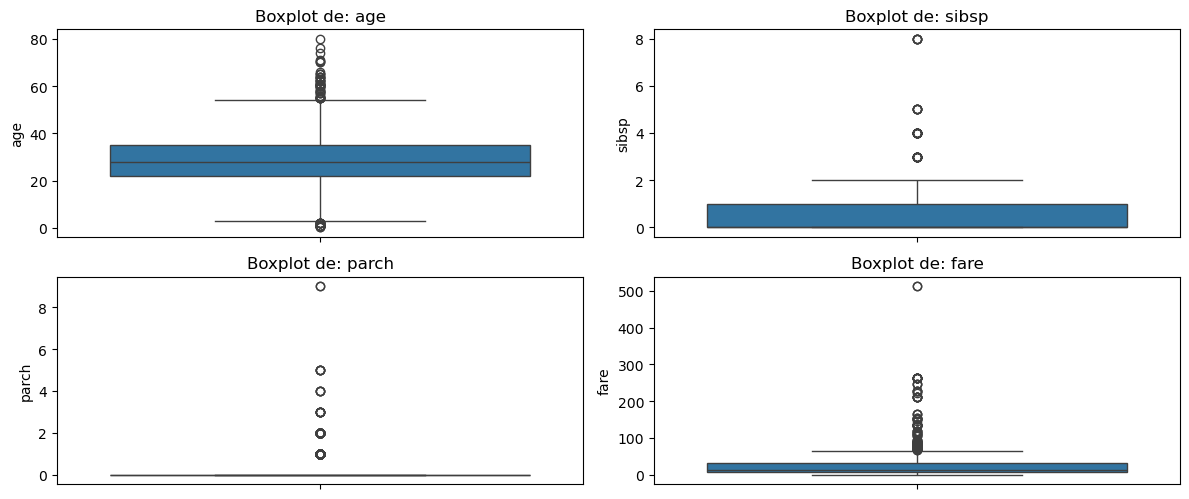

In [294]:
import matplotlib.pyplot as plt
import seaborn as sns
num_cols = ['age', 'sibsp', 'parch', 'fare']
plt.figure(figsize=(12, 10))
for i, col in enumerate(num_cols):
    plt.subplot(4, 2, i + 1)
    sns.boxplot(y=X_train[col])
    plt.title(f'Boxplot de: {col}')
plt.tight_layout()
plt.show()

*Après avoir examiné les valeurs aberrantes détectées, j'ai choisi
de ne pas les remplacer par la médiane et de ne pas supprimer les lignes correspondantes. 
En effet, ces valeurs représentent des observations réelles et restent cohérentes avec la réalité. 
Même si elles sont considérées comme des valeurs aberrantes par la méthode IQR, elles
ne constituent pas nécessairement des erreurs. J'ai donc préféré les conserver afin de préserver les informations du dataset.*

**Partie 3 : Transformation des Données**

***Appliquer des transformations sur les données (normalisation et standardisation)***

In [297]:
X_train = pd.get_dummies(X_train, columns=['sex', 'embarked'], dtype=int)
X_test = pd.get_dummies(X_test, columns=['sex', 'embarked'], dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [304]:
X_train.head()


,pclass,age,sibsp,parch,fare,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
999,3,28.0,0,0,7.7500,1,0,0,1,0
392,2,24.0,1,0,27.7208,1,0,1,0,0
628,3,11.0,4,2,31.2750,1,0,0,0,1
1165,3,25.0,0,0,7.2250,0,1,1,0,0
604,3,16.0,0,0,7.6500,1,0,0,0,1


In [305]:
X_test.head()

,pclass,age,sibsp,parch,fare,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
1028,3,28.0,1,0,24.1500,1,0,0,1,0
1121,3,28.0,1,1,22.3583,0,1,1,0,0
1155,3,28.0,0,0,7.7750,0,1,0,0,1
1251,3,30.5,0,0,8.0500,0,1,0,0,1
721,3,36.0,0,0,7.4958,0,1,0,0,1


**La variable ordinale `pclass` représente la classe du passager. Elle est déjà 
encodée numériquement : 1 pour la première classe, 2 pour 
la deuxième classe et 3 pour la troisième classe. Aucune transformation supplémentaire n a donc été nécessaire.**

**1. Normalisation**

In [343]:
from sklearn.preprocessing import MinMaxScaler
num_cols = ['age', 'sibsp', 'parch', 'fare']
scaler = MinMaxScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])
X_train[num_cols].head()

,age,sibsp,parch,fare
218,0.485356,0.000,0.000000,0.212559
272,0.284519,0.125,0.000000,0.160574
97,0.334728,0.125,0.111111,0.483128
298,0.384937,0.000,0.000000,0.055701
252,0.761506,0.125,0.333333,0.512122


**Après la normalisation, les valeurs des variables **age**, **sibsp**, **parch** et **fare** sont comprises entre 0 et 1. Cette transformation permet de mettre les variables sur la même échelle, tout en conservant leurs différences relatives. Elle facilite ainsi leur utilisation dans les modèles de Machine Learning.**

**2. Standardisation**

In [341]:
from sklearn.preprocessing import StandardScaler
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])
X_train[num_cols].head()

,pclass,age,sibsp,parch,fare,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
218,-1.580849,0.755644,-0.479571,-0.447597,1.569428,1.347040,-1.347040,1.972948,-0.330318,-1.517511
272,-1.580849,-0.488735,0.510785,-0.447597,1.024696,1.347040,-1.347040,-0.506856,-0.330318,0.658974
97,-1.580849,-0.177640,0.510785,0.712389,4.404648,1.347040,-1.347040,1.972948,-0.330318,-1.517511
298,-1.580849,0.133455,-0.479571,-0.447597,-0.074231,-0.742369,0.742369,1.972948,-0.330318,-1.517511
252,-1.580849,2.466665,0.510785,3.032360,4.708462,-0.742369,0.742369,1.972948,-0.330318,-1.517511


**Après la standardisation, les valeurs des variables **age**, **sibsp**, **parch** et **fare** sont transformées autour d'une moyenne proche de 0 et d'un écart-type proche de 1. Les valeurs positives indiquent des valeurs supérieures à la moyenne, tandis que les valeurs négatives indiquent des valeurs inférieures à la moyenne. Cette transformation permet de mettre les variables sur une échelle comparable pour faciliter leur utilisation dans les modèles de Machine Learning.**

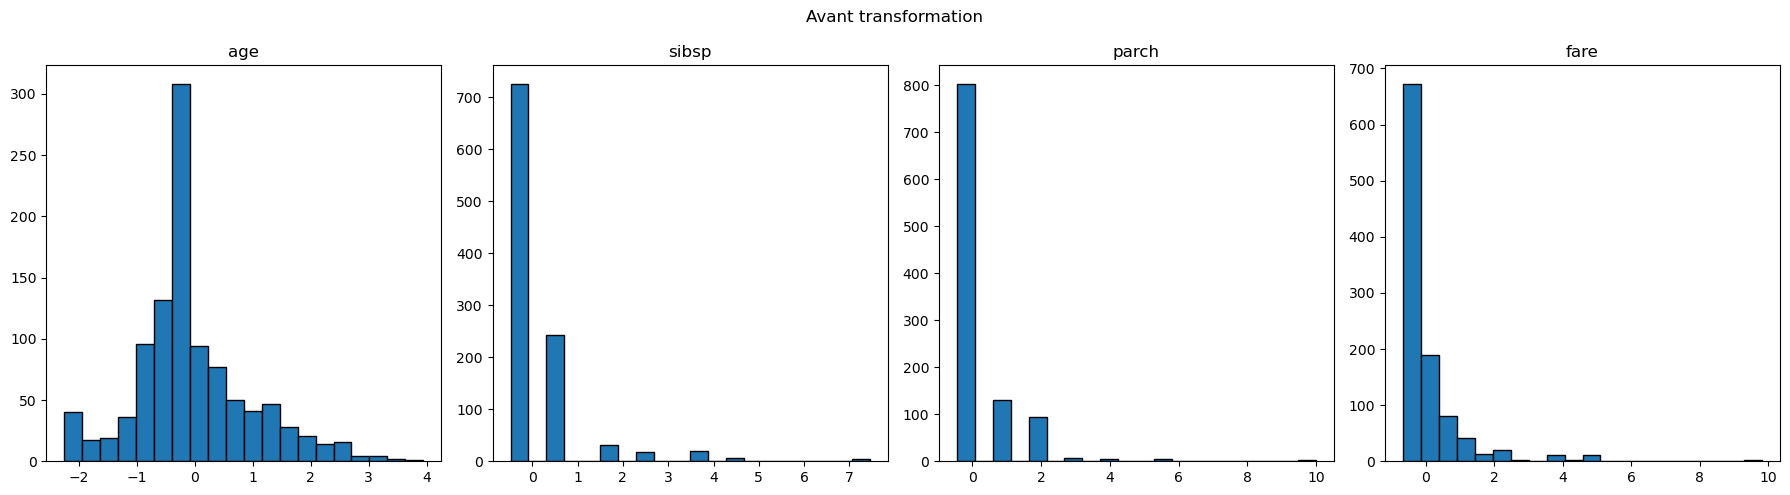

In [326]:
num_cols = ['age', 'sibsp', 'parch', 'fare']
X_train_original = X_train.copy()
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for i, col in enumerate(num_cols):
    axes[i].hist(X_train_original[col].dropna(), bins=20, edgecolor='black')
    axes[i].set_title(col)
plt.suptitle('Avant transformation')
plt.tight_layout()
plt.show()

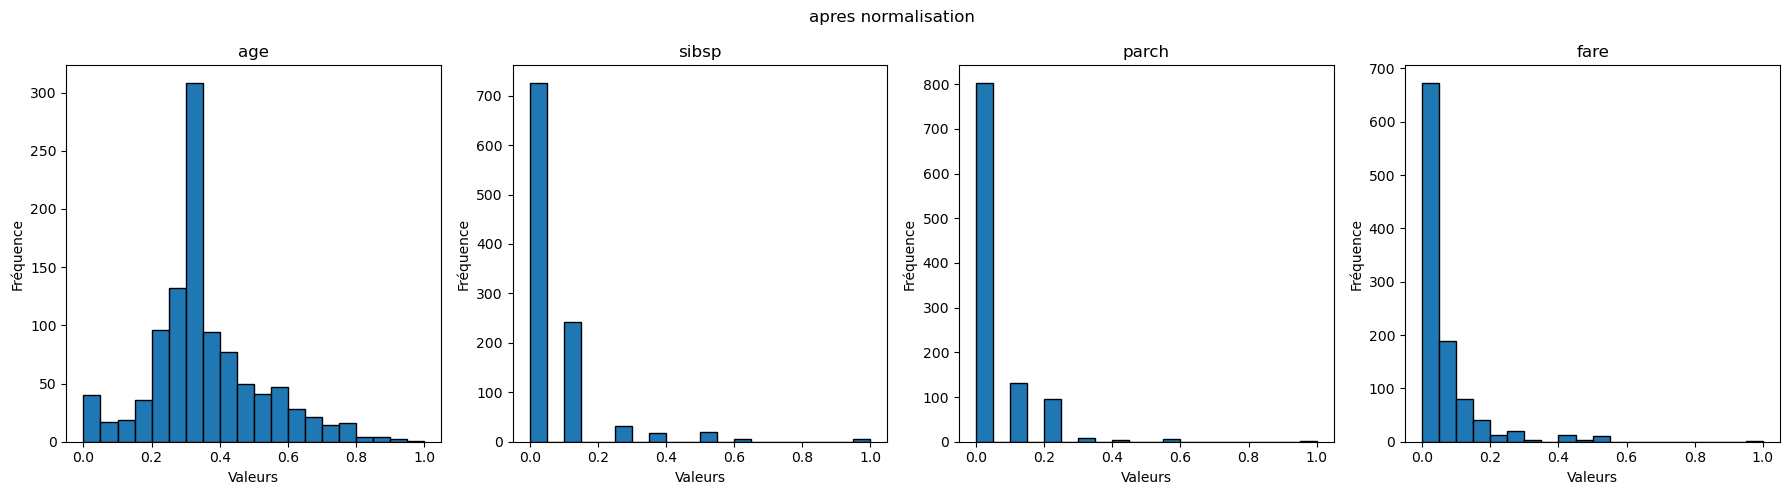

In [346]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for i, col in enumerate(num_cols):
    axes[i].hist(X_train[col].dropna(), bins=20, edgecolor='black')
    axes[i].set_title(col)
    axes[i].set_xlabel('Valeurs')
    axes[i].set_ylabel('Fréquence')

plt.suptitle('apres normalisation ')
plt.tight_layout()
plt.show()

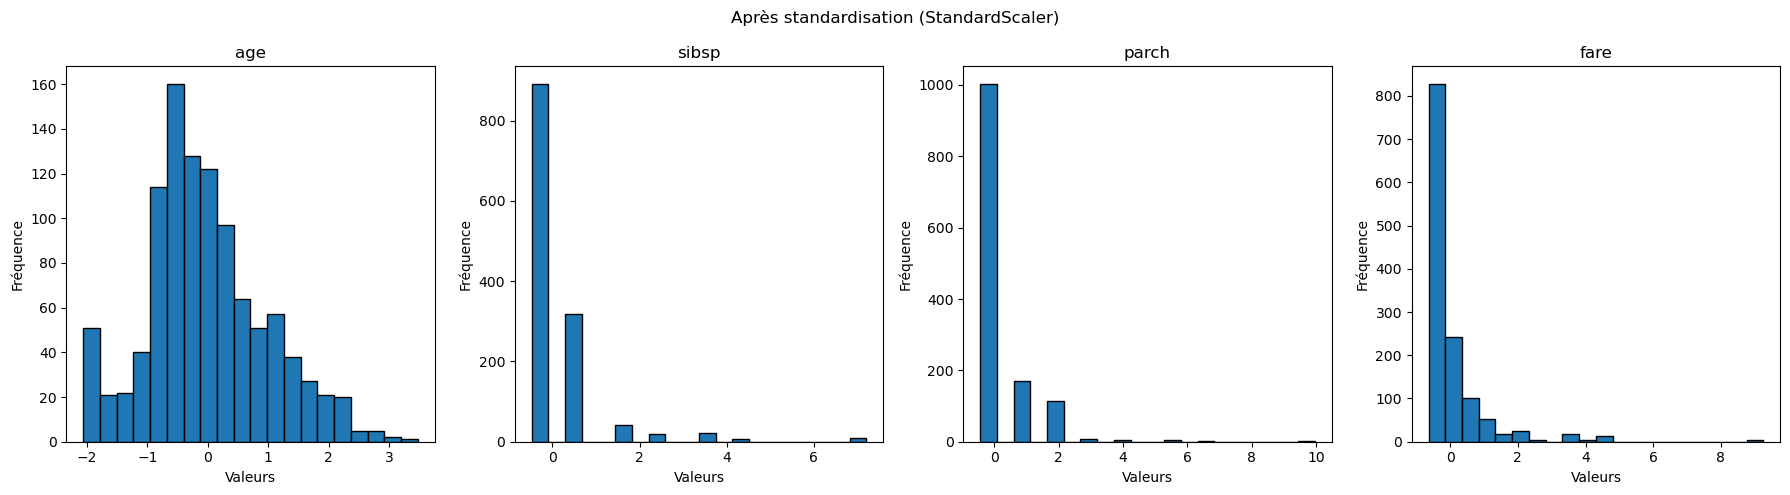

In [344]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for i, col in enumerate(num_cols):
    axes[i].hist(df_st[col].dropna(), bins=20, edgecolor='black')
    axes[i].set_title(col)
    axes[i].set_xlabel('Valeurs')
    axes[i].set_ylabel('Fréquence')
plt.suptitle('Après standardisation (StandardScaler)')
plt.tight_layout()
plt.show()

***comparaison entre les donnees originales et les donnees normalisees et standardisees***

***Partie 4 : Gestion des Données Déséquilibrées***

In [ ]:
Dans cette étape, nous avons étudié la répartition des classes de la variable cible survived afin de vérifier si le dataset Titanic est équilibré ou déséquilibré.

La variable survived contient deux classes :

0 : passagers qui n'ont pas survécu.

1 : passagers qui ont survécu.

Pour vérifier la répartition des classes, nous avons utilisé la fonction value_counts() afin de compter les observations de chaque classe, puis nous avons calculé leurs pourcentages.

In [347]:

print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

survived
0    647
1    400
Name: count, dtype: int64
survived
0    61.795606
1    38.204394
Name: proportion, dtype: float64


**2. Appliquer Random Oversampling**

In [349]:
from imblearn.over_sampling import RandomOverSampler
ros = RandomOverSampler(random_state=42)
X_train_random, y_train_random = ros.fit_resample(
    X_train, y_train)
print("Après Random Oversampling :")
print(y_train_random.value_counts())

Après Random Oversampling :
survived
1    647
0    647
Name: count, dtype: int64


**3. Appliquer SMOTE**

In [348]:
from imblearn.over_sampling import SMOTE
from sklearn.impute import SimpleImputer
X_train_num = X_train.select_dtypes(include=['number'])
imputer = SimpleImputer(strategy='median')
X_train_num = imputer.fit_transform(X_train_num)
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(
    X_train_num, y_train)
print("Après SMOTE :")
print(y_train_smote.value_counts())

Après SMOTE :
survived
1    647
0    647
Name: count, dtype: int64
